# Modelo 9 — KNN por padrão de exames

K-vizinhos mais próximos, com um submodelo para cada padrão de exames disponíveis. É o componente KNN do voto do Modelo 8, separado para ser submetido sozinho.

**Aulas usadas:** 2 (qualidade, ausentes, normalização), 3 (distância Euclidiana), 5 (KNN), 7 (validação e métricas), 10 (padronização por média e desvio padrão)

**Regras da competição respeitadas:**
- O conjunto de teste **não** é usado em nenhuma escolha. Toda avaliação usa validação cruzada só no treino.
- A métrica principal é o **F1-macro**, a mesma do placar do Kaggle. Também mostramos acurácia, precisão e recall de cada classe, como pede o enunciado.

## 1. Bibliotecas e funções do projeto

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from limpeza import carregar          # limpeza e correção de unidades (Aula 2)
from padroes import *                 # PorPadrao, validação e métricas (Aulas 2 e 7)
pd.set_option('display.width', 120)

## 2. Leitura e limpeza dos dados (Aula 2 — qualidade dos dados)

A função `carregar` (arquivo `limpeza.py`) aplica regras linha a linha. Nenhuma estatística é calculada aqui; médias e medianas só são calculadas dentro do treino de cada parte da validação.

| Problema encontrado | Correção |
|---|---|
| 20 registros duplicados do mesmo paciente | removidos |
| Glicose: 44 valores entre 3,1 e 21,3 (mmol/L), o resto entre 47 e 500 (mg/dL) | valores < 35 multiplicados por 18,016 |
| HbA1c: 43 valores entre 27 e 116 (mmol/mol, padrão IFCC), o resto entre 4,7 e 13,1 (%) | valores > 20 convertidos por 0,09148 × v + 2,152 |
| Peso: 23 valores acima de 140 (libras) | divididos por 2,2046 |
| Triglicerídeos com valores extremos (até 5.310) | limitados a 1000 |
| Altura em metros em alguns registros | convertida para cm; IMC calculado |
| Pressão no formato texto `120/80` ou `?` | separada em sistólica e diastólica |
| Grafias diferentes (`F`, `female`, `FEMALE`, `Não`, `0`…) | unificadas |
| Idade 0, −1 ou 999 | recalculada por ano do exame − ano de nascimento |

In [2]:
tr, te = carregar('../dados/kaggle-training/train.csv', '../dados/kaggle-test/test.csv')
y = tr['class'].values
print('treino:', tr.shape, '| teste:', te.shape)
print('classes no treino:', dict(zip(*np.unique(y, return_counts=True))))
tr.head()

### Efeito da correção de unidades

Depois da conversão, os dois exames ficam na mesma escala e separam bem as classes. Nenhum controle tem HbA1c ≥ 6,5% (limite clínico de diabetes).

In [3]:
tr.groupby('class')[['GLICOSE', 'HBA1C']].describe().T.round(1)

class              0      1
GLICOSE count  220.0  241.0
        mean    96.9  152.9
        std     13.9   67.8
        min     68.0   47.0
        25%     86.5  104.5
        50%     95.7  135.1
        75%    105.0  183.8
        max    140.0  500.0
HBA1C   count  192.0  206.0
        mean     5.5    8.1
        std      0.5    1.9
        min      4.6    4.9
        25%      5.1    6.5
        50%      5.4    7.6
        75%      5.8    9.1
        max      6.4   13.1

## 3. Padrões de exames ausentes (Aula 2 — valores ausentes)

Quase 30% dos pacientes não têm glicose, HbA1c ou ambos. Preencher com a mediana faz o paciente parecer saudável, e era exatamente aí que os primeiros modelos erravam.

A solução é **ignorar o atributo ausente** (uma das opções da aula 2): cada paciente vai para um submodelo treinado só com os atributos que ele tem.

| Padrão | Atributos do submodelo |
|---|---|
| glicose e HbA1c | glicose, HbA1c |
| só glicose | glicose + clínicos |
| só HbA1c | HbA1c + clínicos |
| nenhum exame | só clínicos |

Clínicos: triglicerídeos, pressão sistólica, IMC, idade, histórico familiar e atividade física.

In [4]:
cont = pd.DataFrame({
    'treino': pd.Series([NOME_PADRAO[p] for p in padrao_de(tr)]).value_counts(),
    'teste': pd.Series([NOME_PADRAO[p] for p in padrao_de(te)]).value_counts()})
cont['% treino'] = (100 * cont['treino'] / len(tr)).round(1)
cont['% teste'] = (100 * cont['teste'] / len(te)).round(1)
cont

,treino,teste,% treino,% teste
glicose e HbA1c,357,222,68.7,71.2
só glicose,104,53,20.0,17.0
só HbA1c,41,26,7.9,8.3
nenhum exame,18,11,3.5,3.5


## 4. O modelo (Aula 5 — KNN)

Para classificar um paciente:
1. Padroniza cada atributo: `(valor − média) / desvio padrão`, com média e desvio calculados **só no treino** (Aula 10, p. 16). Assim glicose (≈ 100) e HbA1c (≈ 6) pesam igual na distância.
2. Calcula a **distância Euclidiana** até todos os pacientes do treino do mesmo padrão (Aulas 3 e 5).
3. Pega os **K mais próximos**.
4. **Voto simples**: a classe mais frequente entre os K vizinhos. Com K ímpar não há empate.

Testamos também a normalização mín-máx do exemplo da aula 5 (F1 0,885 contra 0,902) e a distância Manhattan da aula 3 (empate). Mantivemos média e desvio padrão com distância Euclidiana.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

def criar_knn(k):
    return PorPadrao(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)))

## 5. Escolha do hiperparâmetro (Aula 7 — validação cruzada)

O único hiperparâmetro é **K**. Testamos valores ímpares: com K pequeno o modelo segue o ruído de poucos vizinhos; com K grande ele mistura pacientes muito diferentes.

Protocolo: validação cruzada estratificada em **5 partes, repetida 4 vezes** (semente 2026), só no treino. Escolhemos o valor com maior F1-macro médio. A avaliação final (seção 6) usa **outra semente (777)**, para não medir o desempenho nas mesmas partes usadas na escolha.

In [6]:
linhas = []
for k in [3, 5, 7, 9, 11, 15, 21]:
    tab, _ = validar(lambda: criar_knn(k), tr, y, semente=2026)
    linhas.append({'K': k, **tab.mean().round(4).to_dict(), 'dp_f1': round(tab['f1_macro'].std(), 4)})
busca = pd.DataFrame(linhas)
busca

,K,f1_macro,acuracia,precisao_macro,recall_diabetes,recall_controle,dp_f1
0,3,0.8874,0.8875,0.8894,0.8583,0.919,0.0258
1,5,0.8932,0.8933,0.8956,0.8620,0.927,0.0276
2,7,0.8946,0.8947,0.8975,0.8574,0.935,0.0270
3,9,0.8980,0.8981,0.9010,0.8574,0.942,0.0278
4,11,0.9004,0.9005,0.9035,0.8593,0.945,0.0264
5,15,0.8960,0.8962,0.9003,0.8491,0.947,0.0308
6,21,0.8921,0.8923,0.8975,0.8389,0.950,0.0310


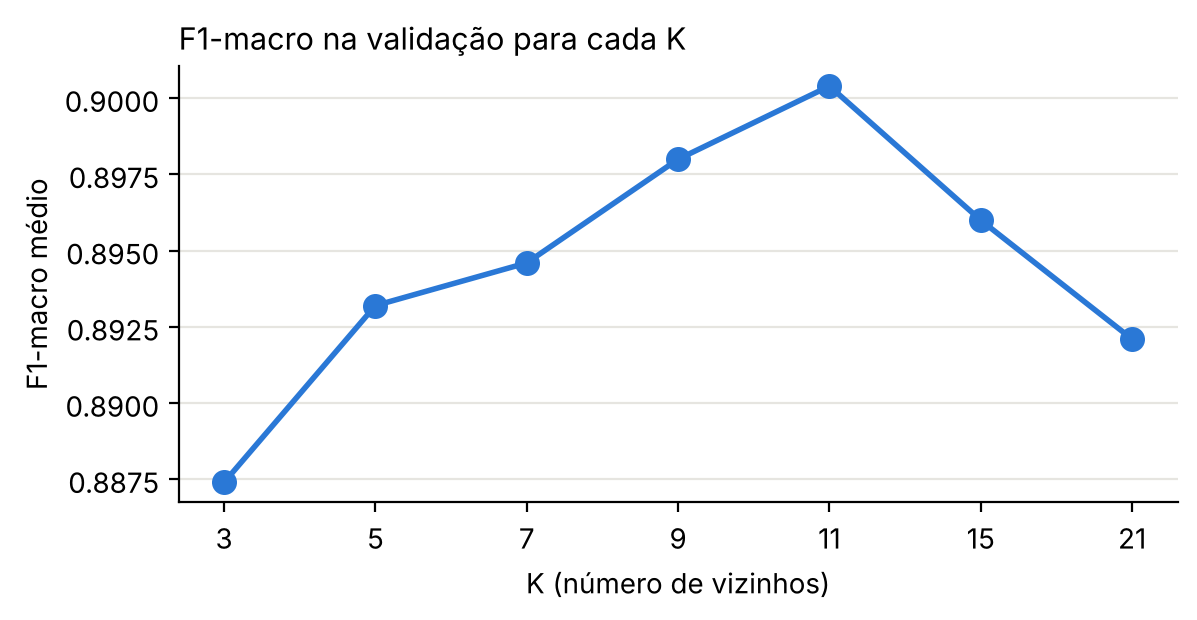

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(busca['K'].astype(str), busca['f1_macro'], color='#2a78d6', linewidth=2, marker='o', markersize=8)
melhor = busca.loc[busca['f1_macro'].idxmax()]
ax.annotate(f"{melhor['f1_macro']:.3f}", (str(melhor['K']), melhor['f1_macro']),
            textcoords='offset points', xytext=(0, 8), ha='center', color='#0b0b0b')
ax.set_xlabel('K (número de vizinhos)'); ax.set_ylabel('F1-macro médio')
ax.set_title('F1-macro na validação para cada K', loc='left', fontsize=11)
ax.grid(axis='y', color='#e6e5e0', linewidth=0.8); ax.set_axisbelow(True)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

In [8]:
K = int(busca.loc[busca['f1_macro'].idxmax(), 'K'])
print('K escolhido:', K)
criar_final = lambda: criar_knn(K)

K escolhido: 11


### Exemplo para a apresentação: os vizinhos de um paciente

Pegamos um paciente "de fronteira" do treino, com os dois exames, cujos vizinhos se dividem entre as classes. Mostramos seus K vizinhos mais próximos (sem contar ele mesmo) no submodelo "glicose e HbA1c".

In [9]:
completos = tr[tr['GLICOSE'].notna() & tr['HBA1C'].notna()].reset_index(drop=True)
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K + 1)).fit(completos[EXAMES].values, completos['class'])
D, I = pipe[-1].kneighbors(pipe[0].transform(completos[EXAMES].values))
votos = completos['class'].values[I[:, 1:]].sum(1)            # votos de diabetes entre os K vizinhos
i = int(np.argmin(np.abs(votos - K / 2) + 0.01 * np.arange(len(votos))))  # o mais dividido
dist, idx = D[[i]], I[[i]]
viz = completos.loc[idx[0][1:], EXAMES + ['class']].assign(distancia=dist[0][1:].round(3))
print('paciente:', completos.loc[i, EXAMES].round(1).to_dict(), '| classe real:', completos.loc[i, 'class'])
print('votos dos vizinhos -> diabetes:', int(viz['class'].sum()), '| controle:', int((viz['class'] == 0).sum()))
viz.round(2)

## 6. Avaliação final — validação cruzada com outra semente (Aula 7)

5 partes × 4 repetições, semente 777. Métricas da aula 7: acurácia, precisão, recall (cobertura) de cada classe e F1. O F1-macro é a média do F1 das duas classes.

In [10]:
tab, prev = validar(criar_final, tr, y, semente=777)
resumo(tab)

,média,desvio padrão
f1_macro,0.896,0.024
acuracia,0.896,0.023
precisao_macro,0.900,0.022
recall_diabetes,0.854,0.040
recall_controle,0.942,0.027


### Matriz de confusão (média por repetição; cada repetição prevê os 520 pacientes uma vez)

In [11]:
matriz_confusao(y, prev)

,previsto controle (0),previsto diabetes (1)
real controle (0),235.5,14.5
real diabetes (1),39.5,230.5


### Onde estão os erros

In [12]:
erros_por_padrao(tr, y, prev)

pacientes  erros_medios  taxa_erro
padrão          classe                                      
glicose e HbA1c controle        173          2.25       0.01
                diabetes        184         22.25       0.12
nenhum exame    controle         11          1.25       0.11
                diabetes          7          2.75       0.39
só HbA1c        controle         19          1.75       0.09
                diabetes         22          3.00       0.14
só glicose      controle         47          9.25       0.20
                diabetes         57         11.50       0.20

## 7. Treino com todos os dados e previsão do teste

O modelo final é treinado com os 520 pacientes do treino e prevê os 312 do teste. O arquivo segue o formato `id,class` do `submission_template.csv`.

In [13]:
modelo = criar_final().fit(tr, y)
prev_teste = modelo.predict(te)
sub = pd.DataFrame({'id': te['id'], 'class': prev_teste})
sub.to_csv('submissao_knn_padroes.csv', index=False)
print('submissao_knn_padroes.csv:', len(sub), 'linhas | diabetes previsto em', f'{prev_teste.mean():.1%}', 'do teste')
print('por padrão de exames:')
print(pd.Series(prev_teste).groupby([NOME_PADRAO[p] for p in padrao_de(te)]).agg(['size', 'mean']).round(2))

submissao_knn_padroes.csv: 312 linhas | diabetes previsto em 44.6% do teste
por padrão de exames:
                 size  mean
glicose e HbA1c   222  0.42
nenhum exame       11  0.64
só HbA1c           26  0.46
só glicose         53  0.49


### Conferência do arquivo

In [14]:
chk = pd.read_csv('submissao_knn_padroes.csv')
tpl = pd.read_csv('../dados/kaggle-test/test.csv', usecols=['id'])
assert list(chk.columns) == ['id', 'class']
assert chk['id'].tolist() == tpl['id'].tolist()
assert set(chk['class']) <= {0, 1}
print('OK: mesmas', len(chk), 'linhas e ordem de ids do teste; classes 0/1')

OK: mesmas 312 linhas e ordem de ids do teste; classes 0/1
